# Pandas

A pandas egy open source, BSD által jóváhagyott modul, melyben nagy teljesítményű és könnyen használható struktúrák, adatelemző eszközök találhatóak.

https://pandas.pydata.org/

## Installlálás

pip install pandas

## Import:

In [1]:
import numpy as np
import pandas as pd

A pandas 2 class-t biztosít adatfeldolgozásra:

 - Series: egy egy dimenziós névvel ellátot tömb mely bármilyen adatot tartalmazhat. Pl.: integer, string, object, stb.

 - DataFrame: egy két dimenziós adatszerkezet mely két dimenziós tömbök mintájára készült. Hasonlít egy table objektumra sorokkal és oszlopokkal.

## Objektum létrehozás

### Series

#### Létrehozunk egy Series-t listával, megengedve a pandasnak, hogy az alapértelmezett RangeIndex-et használja

In [ ]:
s = pd.Series([1,5,7,32,-1])
s

0     1
1     5
2     7
3    32
4    -1
dtype: int64

In [7]:
list(pd.RangeIndex(-1,10,3))

[-1, 2, 5, 8]

In [12]:
s[0] #s[[0]]

np.int64(1)

In [14]:
s[[0, 2]]

0    1
2    7
dtype: int64

### DataFrame

#### Létrehozunk egy DataFrame-et egy dictionary segítségével, melyben bármilyen típusú objecktum lehet. Itt a kulcsok lesznek az oszlopok címei.

In [16]:
# 4 sor adatai
print(
    pd.Timestamp("20261116"),
    pd.Series(3, dtype="float32", index=list(range(4))),
    np.array([9]*4),
    pd.Categorical(["cat", "dog", "dog", "dog"])
)

2026-11-16 00:00:00 0    3.0
1    3.0
2    3.0
3    3.0
dtype: float32 [9 9 9 9] ['cat', 'dog', 'dog', 'dog']
Categories (2, object): ['cat', 'dog']


In [19]:
df = pd.DataFrame({
        #[oszlopcímke]: [érték(ek)],
        "A": 1.0,
        "B": pd.Timestamp("20261116"),
        "C": pd.Series(3, dtype="float32", index=list(range(4))),
        "D": np.array([9]*4),
        "E": pd.Categorical(["cat", "dog", "dog", "dog"]),
        "F": "thingy"
    }
)

df

,A,B,C,D,E,F
0,1.0,2026-11-16,3.0,9,cat,thingy
1,1.0,2026-11-16,3.0,9,dog,thingy
2,1.0,2026-11-16,3.0,9,dog,thingy
3,1.0,2026-11-16,3.0,9,dog,thingy


In [22]:
df.dtypes

A          float64
B    datetime64[s]
C          float32
D            int64
E         category
F           object
dtype: object

#### Készítsünk DataFrame-et Numpy array-el. Adjunk meg datetime index-et a date_range() használatával és nevezzük el az oszlopokat:

In [55]:
index = pd.date_range("20261116", periods=6, freq="D")
index

DatetimeIndex(['2026-11-16', '2026-11-17', '2026-11-18', '2026-11-19',
               '2026-11-20', '2026-11-21'],
              dtype='datetime64[ns]', freq='D')

In [56]:
df = pd.DataFrame(np.random.randn(6, 4), index=index, columns=list("ABCD"))
df

,A,B,C,D
2026-11-16,1.005993,0.468823,-2.210827,-1.026694
2026-11-17,-0.280473,0.730292,0.963256,1.501753
2026-11-18,-0.083477,1.140342,0.061303,0.665233
2026-11-19,0.730108,-0.155920,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044
2026-11-21,0.292717,1.243743,-0.422934,0.170098


In [49]:
df.dtypes

A    float64
B    float64
C    float64
D    float64
dtype: object

## Adatok visszakérése

Használjuk a  DataFrame.head() vagy a  DataFrame.tail() függvényeket, hogy elérjük a DataFrame felső vagy alsó sorait:

In [57]:
df.head()

,A,B,C,D
2026-11-16,1.005993,0.468823,-2.210827,-1.026694
2026-11-17,-0.280473,0.730292,0.963256,1.501753
2026-11-18,-0.083477,1.140342,0.061303,0.665233
2026-11-19,0.730108,-0.155920,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044


In [58]:
df.tail()

,A,B,C,D
2026-11-17,-0.280473,0.730292,0.963256,1.501753
2026-11-18,-0.083477,1.140342,0.061303,0.665233
2026-11-19,0.730108,-0.155920,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044
2026-11-21,0.292717,1.243743,-0.422934,0.170098


Írassuk ki a DataFrame.index-et vagy a DataFrame.columns-t:

In [59]:
df.index

DatetimeIndex(['2026-11-16', '2026-11-17', '2026-11-18', '2026-11-19',
               '2026-11-20', '2026-11-21'],
              dtype='datetime64[ns]', freq='D')

In [60]:
df.columns

Index(['A', 'B', 'C', 'D'], dtype='object')

Készítsünk NumPy reprezentációt a következő adatokból a DataFrame.to_numpy() segítségével az indexek és oszlopcímek nélkül:

In [61]:
df.to_numpy()

array([[ 1.00599297,  0.46882304, -2.21082695, -1.0266937 ],
       [-0.28047286,  0.73029193,  0.96325604,  1.50175289],
       [-0.08347663,  1.14034225,  0.06130294,  0.66523334],
       [ 0.73010804, -0.15591978, -1.86036287, -1.50536467],
       [ 0.74527541,  0.47935191,  0.47588319, -0.98004434],
       [ 0.29271749,  1.24374313, -0.42293396,  0.17009758]])

A describe() egy gyors leírást ad az adatokról:

In [62]:
df.describe()

,A,B,C,D
count,6.000000,6.000000,6.000000,6.000000
mean,0.401691,0.651105,-0.498947,-0.195836
std,0.510627,0.512027,1.279998,1.164245
min,-0.280473,-0.155920,-2.210827,-1.505365
25%,0.010572,0.471455,-1.501006,-1.015031
50%,0.511413,0.604822,-0.180816,-0.404973
75%,0.741484,1.037830,0.372238,0.541449
max,1.005993,1.243743,0.963256,1.501753


Transzponáljuk a DataFrame-et:

In [63]:
df.T

,2026-11-16,2026-11-17,2026-11-18,2026-11-19,2026-11-20,2026-11-21
A,1.005993,-0.280473,-0.083477,0.730108,0.745275,0.292717
B,0.468823,0.730292,1.140342,-0.155920,0.479352,1.243743
C,-2.210827,0.963256,0.061303,-1.860363,0.475883,-0.422934
D,-1.026694,1.501753,0.665233,-1.505365,-0.980044,0.170098


Ragadjunk ki 3 sort a DataFrame-ből:

In [79]:
df2 = df.sample(3)
df2

,A,B,C,D
2026-11-21,0.292717,1.243743,-0.422934,0.170098
2026-11-17,-0.280473,0.730292,0.963256,1.501753
2026-11-20,0.745275,0.479352,0.475883,-0.980044


A sort_index() tengely szerint rendez:

In [87]:
df2.sort_index(axis=0, ascending=True) # -> sor szerint rendez

,A,B,C,D
2026-11-17,-0.280473,0.730292,0.963256,1.501753
2026-11-20,0.745275,0.479352,0.475883,-0.980044
2026-11-21,0.292717,1.243743,-0.422934,0.170098


In [90]:
df2.sort_index(axis=1, ascending=False) # -> oszlop szerint rendez

,D,C,B,A
2026-11-21,0.170098,-0.422934,1.243743,0.292717
2026-11-17,1.501753,0.963256,0.730292,-0.280473
2026-11-20,-0.980044,0.475883,0.479352,0.745275


A sort_values() érték szerint rendez:

In [94]:
df2.sort_values(by="C")

,A,B,C,D
2026-11-21,0.292717,1.243743,-0.422934,0.170098
2026-11-20,0.745275,0.479352,0.475883,-0.980044
2026-11-17,-0.280473,0.730292,0.963256,1.501753


## Selection

Komplex projektekhez ajánlott optimalizálni az adatok elérését, pl: DataFrame.at(), DataFrame.iat(), DataFrame.loc() and DataFrame.iloc()

### Getitem

A DataFrame-ek esetében egy cím megadásával egy oszlopot kapunk vissza mely megegyezik egy Series-el:

In [95]:
df["C"]

2026-11-16   -2.210827
2026-11-17    0.963256
2026-11-18    0.061303
2026-11-19   -1.860363
2026-11-20    0.475883
2026-11-21   -0.422934
Freq: D, Name: C, dtype: float64

Ahhoz, hogy DataFrame-et kapjunk, adjunk meg egy szeletet megfelelő sorszámokkal:

In [ ]:
df[2::] # -> 0-1. nincs, többi sor van

,A,B,C,D
2026-11-18,-0.083477,1.140342,0.061303,0.665233
2026-11-19,0.730108,-0.155920,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044
2026-11-21,0.292717,1.243743,-0.422934,0.170098


In [107]:
df["20261118":"20261120"]

,A,B,C,D
2026-11-18,-0.083477,1.140342,0.061303,0.665233
2026-11-19,0.730108,-0.155920,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044


### Kiválasztás cím szerint

In [109]:
index[0]

Timestamp('2026-11-16 00:00:00')

In [ ]:
df.loc[index[0]] # 2026.11.16. sora

A    1.005993
B    0.468823
C   -2.210827
D   -1.026694
Name: 2026-11-16 00:00:00, dtype: float64

In [111]:
df.loc["20261116"]

A    1.005993
B    0.468823
C   -2.210827
D   -1.026694
Name: 2026-11-16 00:00:00, dtype: float64

Összes sor kilistázása (:) megadott oszlopcímekkel:

In [114]:
df.loc[:, ["A", "D"]]

,A,D
2026-11-16,1.005993,-1.026694
2026-11-17,-0.280473,1.501753
2026-11-18,-0.083477,0.665233
2026-11-19,0.730108,-1.505365
2026-11-20,0.745275,-0.980044
2026-11-21,0.292717,0.170098


"A" és "B" oszlop megjelenítése 2026.11.17-19. között:

In [115]:
df.loc["20261117":"20261119", ["A", "B"]]

,A,B
2026-11-17,-0.280473,0.730292
2026-11-18,-0.083477,1.140342
2026-11-19,0.730108,-0.155920


Egy sor és oszlop kiválasztása skalárt ad vissza:

In [ ]:
df.loc["20261118", "A"]

np.float64(-0.08347663323869388)

A skalár gyorsabb lekérdezéséhez:

In [117]:
df.at["20261118", "A"] # -> "at" konkrét metszet lekérdezéséhez

np.float64(-0.08347663323869388)

### Pozíció szerinti kilistázás: iloc()

Válsszuk ki az adatokat a pozíciójuk alapján:

In [118]:
df.iloc[1] # -> 1. sor adatai 

A   -0.280473
B    0.730292
C    0.963256
D    1.501753
Name: 2026-11-17 00:00:00, dtype: float64

Hasonlóan viselkednek, mint a Numpy/Python slice-ok:

In [120]:
df.iloc[3:5, 1:3] # -> 3-4. sor 1-2. oszlopa

,B,C
2026-11-19,-0.155920,-1.860363
2026-11-20,0.479352,0.475883


Integer pozíciók listája:

In [123]:
df.iloc[[5, 1, 3], [0, 3]]

,A,D
2026-11-21,0.292717,0.170098
2026-11-17,-0.280473,1.501753
2026-11-19,0.730108,-1.505365


Explicit sorokra szűrés:

In [ ]:
df.iloc[:, 1] # -> "B" oszlop sorai

2026-11-16    0.468823
2026-11-17    0.730292
2026-11-18    1.140342
2026-11-19   -0.155920
2026-11-20    0.479352
2026-11-21    1.243743
Freq: D, Name: B, dtype: float64

Explicit oszlopokra szűrés:

In [ ]:
df.iloc[5, :] # -> utolsó sor oszlopai

A    0.292717
B    1.243743
C   -0.422934
D    0.170098
Name: 2026-11-21 00:00:00, dtype: float64

Explicit értékre szűrés:

In [ ]:
df.iat[2, 1] # 18. "B" oszlop értéke

np.float64(1.1403422497032598)

### Boolean indexelés

Válasszuk ki a sorokat ahol df.A > 0.5:

In [133]:
df["A"]>0.5

2026-11-16     True
2026-11-17    False
2026-11-18    False
2026-11-19     True
2026-11-20     True
2026-11-21    False
Freq: D, Name: A, dtype: bool

In [134]:
df[df["A"]>0.5]

,A,B,C,D
2026-11-16,1.005993,0.468823,-2.210827,-1.026694
2026-11-19,0.730108,-0.155920,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044


Értékek kilistázása DataFrame-ből amik egy boolean kritériumnak megfelelnek:

In [135]:
df[df > 0.5]

,A,B,C,D
2026-11-16,1.005993,NaN,NaN,NaN
2026-11-17,NaN,0.730292,0.963256,1.501753
2026-11-18,NaN,1.140342,NaN,0.665233
2026-11-19,0.730108,NaN,NaN,NaN
2026-11-20,0.745275,NaN,NaN,NaN
2026-11-21,NaN,1.243743,NaN,NaN


isin() metódus használata filterként:

In [ ]:
df2 = df.copy()
df2["E"] = ["cat", "dog", "hamster", "cat", "dog", "cat"]
df2

In [140]:
df2[df2["E"].isin(["dog"])]

,A,B,C,D,E
2026-11-17,-0.280473,0.730292,0.963256,1.501753,dog
2026-11-20,0.745275,0.479352,0.475883,-0.980044,dog


### Setting

Értékek beállítása pozíció szerint:

In [141]:
df

,A,B,C,D
2026-11-16,1.005993,0.468823,-2.210827,-1.026694
2026-11-17,-0.280473,0.730292,0.963256,1.501753
2026-11-18,-0.083477,1.140342,0.061303,0.665233
2026-11-19,0.730108,-0.155920,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044
2026-11-21,0.292717,1.243743,-0.422934,0.170098


In [146]:
df3 = df.copy()
df3.iat[3, 1] = 0
df3

,A,B,C,D
2026-11-16,1.005993,0.468823,-2.210827,-1.026694
2026-11-17,-0.280473,0.730292,0.963256,1.501753
2026-11-18,-0.083477,1.140342,0.061303,0.665233
2026-11-19,0.730108,0.000000,-1.860363,-1.505365
2026-11-20,0.745275,0.479352,0.475883,-0.980044
2026-11-21,0.292717,1.243743,-0.422934,0.170098


Értékek beállítása Numpy array megadásával:

In [148]:
df.loc[:, "A"] = np.array([5] * len(df))
df

,A,B,C,D
2026-11-16,5.0,0.468823,-2.210827,-1.026694
2026-11-17,5.0,0.730292,0.963256,1.501753
2026-11-18,5.0,1.140342,0.061303,0.665233
2026-11-19,5.0,-0.155920,-1.860363,-1.505365
2026-11-20,5.0,0.479352,0.475883,-0.980044
2026-11-21,5.0,1.243743,-0.422934,0.170098


A where operandus:

In [151]:
df4 = df.copy()
df4[df4 < 0] = -df4
df4

,A,B,C,D
2026-11-16,5.0,0.468823,2.210827,1.026694
2026-11-17,5.0,0.730292,0.963256,1.501753
2026-11-18,5.0,1.140342,0.061303,0.665233
2026-11-19,5.0,0.155920,1.860363,1.505365
2026-11-20,5.0,0.479352,0.475883,0.980044
2026-11-21,5.0,1.243743,0.422934,0.170098


### Hiányos adatok

Numpy adattípusokhoz az np.nan reprezentálja a hiányos adatokat. Ez alapértelmezetten nem szerepel a számításokban.

Az újraindexelés lehetővé teszi egy megadott tengely indexének megváltoztatását/hozzáadását/kitörlését. Ez egy másolatot ad vissza az adatokról:

In [ ]:
df5 = df.reindex(index=index[0:4], columns=list(df.columns) + ["E"])
df5.iloc[[1,3], 4] = 1
df5

,A,B,C,D,E
2026-11-16,5.0,0.468823,-2.210827,-1.026694,NaN
2026-11-17,5.0,0.730292,0.963256,1.501753,1.0
2026-11-18,5.0,1.140342,0.061303,0.665233,NaN
2026-11-19,5.0,-0.155920,-1.860363,-1.505365,1.0


dropna() elhagy minden sort, ahol van hiányos érték:

In [ ]:
df5.dropna(how="any")

,A,B,C,D,E
2026-11-17,5.0,0.730292,0.963256,1.501753,1.0
2026-11-19,5.0,-0.155920,-1.860363,-1.505365,1.0


fillna() feltölti a hiányos adatokat:

In [160]:
df5.fillna(6)

,A,B,C,D,E
2026-11-16,5.0,0.468823,-2.210827,-1.026694,6.0
2026-11-17,5.0,0.730292,0.963256,1.501753,1.0
2026-11-18,5.0,1.140342,0.061303,0.665233,6.0
2026-11-19,5.0,-0.155920,-1.860363,-1.505365,1.0


isna() visszaadja a boolean értéket a hiányzó értékekre:

In [161]:
df5.isna()

,A,B,C,D,E
2026-11-16,False,False,False,False,True
2026-11-17,False,False,False,False,False
2026-11-18,False,False,False,False,True
2026-11-19,False,False,False,False,False


## Operations

### Statisztika

Általában kihagyjuk a hiányos adatokat.

Számoljuk ki az oszlopok átlagát:

In [166]:
df5.mean()

A    5.000000
B    0.545884
C   -0.761658
D   -0.091268
E    1.000000
dtype: float64

Számoljuk ki a sorok átlagát:

In [169]:
df5.mean(axis=1)

2026-11-16    0.557826
2026-11-17    1.839060
2026-11-18    1.716720
2026-11-19    0.495671
Freq: D, dtype: float64

Ha egyszerre két Series-vel vagy DataFrame-vel dolgozunk, melyeknek küldönböznek az indexei vagy az oszlopai, akkor a pandas a két objektum úniója szerint fogja rendezni az indexeket vagy oszlopokat. 
Ezen felül a pandas automatikusan broadcastol a megfelelő dimenziók szerint, hogy kitöltse az üres helyeket np.nan-al.

In [177]:
s = pd.Series([1, 2, 5, np.nan, 6, -1], index=index)
s = s.shift(2)
s

2026-11-16    NaN
2026-11-17    NaN
2026-11-18    1.0
2026-11-19    2.0
2026-11-20    5.0
2026-11-21    NaN
Freq: D, dtype: float64

In [181]:
df.sub(s, axis="index")

,A,B,C,D
2026-11-16,NaN,NaN,NaN,NaN
2026-11-17,NaN,NaN,NaN,NaN
2026-11-18,4.0,0.140342,-0.938697,-0.334767
2026-11-19,3.0,-2.155920,-3.860363,-3.505365
2026-11-20,0.0,-4.520648,-4.524117,-5.980044
2026-11-21,NaN,NaN,NaN,NaN


### Felhasználó által definiált függvények

Az agg() és a transform() alkalmaz egy felhasználó által definiált függvényt, redukálja vagy broadcastolja az eredményt.

In [183]:
df.transform(lambda x: -x)

,A,B,C,D
2026-11-16,-5.0,-0.468823,2.210827,1.026694
2026-11-17,-5.0,-0.730292,-0.963256,-1.501753
2026-11-18,-5.0,-1.140342,-0.061303,-0.665233
2026-11-19,-5.0,0.155920,1.860363,1.505365
2026-11-20,-5.0,-0.479352,-0.475883,0.980044
2026-11-21,-5.0,-1.243743,0.422934,-0.170098


In [184]:
df.agg(lambda x: np.mean(x))

A    5.000000
B    0.651105
C   -0.498947
D   -0.195836
dtype: float64

### Előfordulási mennyiségek

In [187]:
s = pd.Series(np.random.randint(8, 15, size=10))
s

0    14
1    13
2    11
3    11
4     8
5     9
6    13
7     8
8    14
9    13
dtype: int32

In [ ]:
s.value_counts()

13    3
14    2
11    2
8     2
9     1
Name: count, dtype: int64

### String Metódusok

A Series rengeteg string feldolgozáshoz használt metódust tartalmaz az str atribútumában, melyek könnyebbé teszik az egyes elemek feldolgozását:

## Összefűzés

### Konkatenálás

A pandas számos lehetőséget ad a Series és DataFrame objektumot különböző módú összefűzésére és kombinálására bármilyen halmaz művelet vagy relációs algebrai művelet alapján a join / merge típusú operációk használatával.

Pandas objektumok konkatenálása sor szerint a concat() függvénnyel:

### Join

A merge() lehetővé teszi az SQL stílusú join műveleteket specifikus oszlopokra:

merge() egyedi kulcsokkal:

### Grouping

Az adatok csoportosítása megadott kritériumok alapján

Függvények használata az egyes csoportokon

Az adatok összefűzése egy adat szerkezetbe

Oszlopcímek alapján csoportosítás: kiválasztjuk az oszlopcímeket és a sum() függvény segítségévek összegezzük az eredményt

Csoportosítás több oszlop cím szerint MultiIndex-et eredményez.

### Átformázás

#### Stack


A stack() metódus "összetömörít" egy szintet a DataFrame oszlopaiban:

Egy "stackelt" DataFrame vagy Series esetén az inverz operandus az unstack() mely alapértelmezetten unstack-eli az utolsó szintet:

### Pivot táblák

pivot_table() pivotálja a DataFrame-et sepcifikálva az értékeket, indexeket és oszlopokat.

## Time series

A pandasban vannak egyszerű, erős, és hatékony funkciók újramintavételezésre a frekvenciaátalakítás során (úgy mint másodpercenkénti adatokat 5 percenkénti adatokká konvertálni) Ez mindennapos például pénzügyi tranzakcióknál.

In [40]:
rng = pd.date_range("1/1/2012", periods=100, freq="S")
rng

In [41]:
ts = pd.Series(np.random.randint(0, 500, len(rng)), index=rng)
ts

2012-01-01 00:00:00    130
2012-01-01 00:00:01    306
2012-01-01 00:00:02    308
2012-01-01 00:00:03    160
2012-01-01 00:00:04    401
                      ... 
2012-01-01 00:01:35    453
2012-01-01 00:01:36     28
2012-01-01 00:01:37    352
2012-01-01 00:01:38    466
2012-01-01 00:01:39    299
Freq: s, Length: 100, dtype: int32

In [42]:
ts.resample("5Min").sum()

2012-01-01    27135
Freq: 5min, dtype: int32

Series.tz_localize() lokalizál egy time series-t a helyi idő zómára:

In [45]:
rng = pd.date_range("3/6/2012 00:00", periods=5, freq="D")
rng

DatetimeIndex(['2012-03-06', '2012-03-07', '2012-03-08', '2012-03-09',
               '2012-03-10'],
              dtype='datetime64[ns]', freq='D')

In [46]:
ts = pd.Series(np.random.randn(len(rng)), rng)
ts

2012-03-06   -0.050891
2012-03-07    0.431576
2012-03-08    0.349853
2012-03-09   -0.554226
2012-03-10    0.055057
Freq: D, dtype: float64

In [47]:
ts_utc = ts.tz_localize("UTC")
ts_utc

2012-03-06 00:00:00+00:00   -0.050891
2012-03-07 00:00:00+00:00    0.431576
2012-03-08 00:00:00+00:00    0.349853
2012-03-09 00:00:00+00:00   -0.554226
2012-03-10 00:00:00+00:00    0.055057
Freq: D, dtype: float64

Series.tz_convert() konvertál időzónák között:

In [48]:
ts_utc.tz_convert("US/Eastern")

2012-03-05 19:00:00-05:00   -0.050891
2012-03-06 19:00:00-05:00    0.431576
2012-03-07 19:00:00-05:00    0.349853
2012-03-08 19:00:00-05:00   -0.554226
2012-03-09 19:00:00-05:00    0.055057
Freq: D, dtype: float64

Egy nem fix időtartam (munkanap) hozzáadása egy time series-hez:

In [49]:
rng

DatetimeIndex(['2012-03-06', '2012-03-07', '2012-03-08', '2012-03-09',
               '2012-03-10'],
              dtype='datetime64[ns]', freq='D')

In [50]:
rng + pd.offsets.BusinessDay(5)

DatetimeIndex(['2012-03-13', '2012-03-14', '2012-03-15', '2012-03-16',
               '2012-03-16'],
              dtype='datetime64[ns]', freq=None)

## Kategóriák

A pandas képes kategorikus adatokat tárolni DataFramekben

In [51]:
df = pd.DataFrame(
    {"id": [1, 2, 3, 4, 5, 6], "raw_grade": ["a", "b", "b", "a", "a", "e"]}
)
df

,id,raw_grade
0,1,a
1,2,b
2,3,b
3,4,a
4,5,a
5,6,e


A nyers érdemjegyek konvertálása kategórikus adattípussá:

In [52]:
df["grade"] = df["raw_grade"].astype("category")
df["grade"]

0    a
1    b
2    b
3    a
4    a
5    e
Name: grade, dtype: category
Categories (3, object): ['a', 'b', 'e']

Kategóriák átnevezése:

In [53]:
new_categories = ["very good", "good", "very bad"]

In [54]:
df["grade"] = df["grade"].cat.rename_categories(new_categories)

A kategóriák átrendezése és egyben hiányzó kategóriák hozzáadása (a Series.cat() alatti metódusok visszatérési értéke egy Series):

In [56]:
df["grade"] = df["grade"].cat.set_categories(
    ["very bad", "bad", "medium", "good", "very good"]
)
df["grade"]

0    very good
1         good
2         good
3    very good
4    very good
5     very bad
Name: grade, dtype: category
Categories (5, object): ['very bad', 'bad', 'medium', 'good', 'very good']

A kategóriákban a rendezés nem abc szerinti:

In [57]:
df.sort_values(by="grade")

,id,raw_grade,grade
5,6,e,very bad
1,2,b,good
2,3,b,good
0,1,a,very good
3,4,a,very good
4,5,a,very good


Ha a kategória oszlop szerint rendezünk és az observed=False-ra állítjuk akkor láthatjuk az üres kategóriákat is:

In [58]:
df.groupby("grade", observed=False).size()

grade
very bad     1
bad          0
medium       0
good         2
very good    3
dtype: int64

## Plotolás

A standard konvenció szerint a matplotlibet használjuk:

In [60]:
# pip install matplotlib
import matplotlib.pyplot as plt

In [61]:
plt.close("all")

A plt.close metódus-t a figure window bezárására használjuk:

In [63]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range("1/1/2000", periods=1000))
ts

2000-01-01    0.129651
2000-01-02    1.680080
2000-01-03    0.545413
2000-01-04   -1.337971
2000-01-05    1.065813
                ...   
2002-09-22   -0.864567
2002-09-23   -0.056101
2002-09-24    3.438526
2002-09-25   -1.384494
2002-09-26    1.047728
Freq: D, Length: 1000, dtype: float64

In [64]:
ts = ts.cumsum()

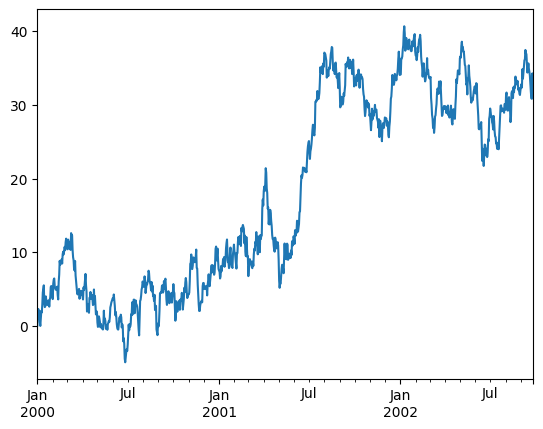

In [ ]:
ts.plot()

plot() minden oszlopot kiplotol:

In [66]:
df = pd.DataFrame(
    np.random.randn(1000, 4), index=ts.index, columns=["A", "B", "C", "D"]
)
df

,A,B,C,D
2000-01-01,-1.061895,0.628602,-1.087073,0.010951
2000-01-02,-0.819719,1.031698,0.658740,0.499495
2000-01-03,0.129104,0.233276,0.775687,-2.484127
2000-01-04,0.347797,-0.911296,0.029602,-0.815931
2000-01-05,1.150346,0.172004,0.532773,-0.086320
...,...,...,...,...
2002-09-22,-0.916040,-0.324001,-0.313121,1.468695
2002-09-23,-0.052370,-1.206105,1.351543,1.171407
2002-09-24,-1.011252,0.534481,0.605147,0.310948
2002-09-25,1.966073,-0.684719,0.650741,1.500704


In [67]:
df = df.cumsum()

In [69]:
plt.figure()

<Figure size 640x480 with 0 Axes>

<Figure size 640x480 with 0 Axes>

<Axes: >

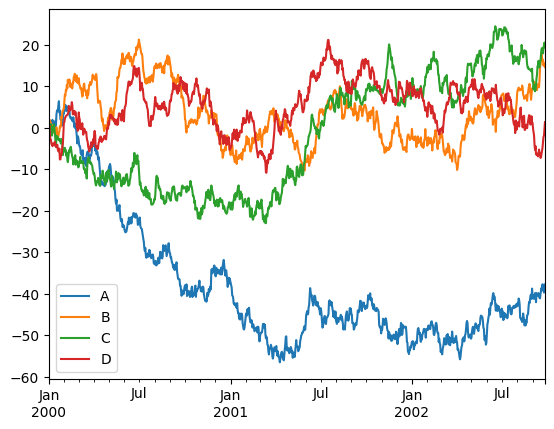

In [70]:
df.plot()

## Adatok importálása és exportálása

### CSV

CSV fájlba írás a DataFrame.to_csv() paranccsal.

In [71]:
df = pd.DataFrame(np.random.randint(0, 5, (10, 5)))

In [72]:
df.to_csv("foo.csv")

CSV fájlból olvasás a read_csv() paranccsal.

In [73]:
pd.read_csv("foo.csv")

,Unnamed: 0,0,1,2,3,4
0,0,2,0,2,0,3
1,1,2,2,0,2,1
2,2,1,2,4,1,1
3,3,1,1,4,1,4
4,4,4,2,3,0,2
5,5,0,3,4,2,1
6,6,3,4,3,4,3
7,7,1,1,3,4,1
8,8,4,4,3,2,1
9,9,4,0,2,2,3


Más típusok is lehetnek például: Parquet, Excel,

## Cookbook

https://pandas.pydata.org/docs/user_guide/cookbook.html#cookbook